# Multiwavelength fold — figures

The fold-train figures, made **only from saved results**. Nothing is fitted
here and `curlew` and `torch` are not needed: numpy and matplotlib only.

The main figure compares the two fits of `04b_multiwavelength_fold_fit`
(`results/shear/` and `results/rk4/`): run 04b first (it fits both).
The numbers at the end are printed for `INTEGRATOR` (the shear fit, unless that line is changed).

| file | written by | contents |
|---|---|---|
| `data/big_fold_observations.npz` | `04a_multiwavelength_fold_data` | traces, clumps, bedding |
| `results/<INTEGRATOR>/fit.npz` | `04b_multiwavelength_fold_fit` | lithology, restored traces, strain, pathlines, reference grid, det, shear modes |
| `results/<INTEGRATOR>/summary.json` | `04b_multiwavelength_fold_fit` | the numbers quoted in the text |

Main text, in `figures/`: `fig04_big_fold` (contacts; lithology from the shear
sequence and from RK4, same basis).


## Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
import big_fold_inputs as bfi
figstyle.apply()

INTEGRATOR = "shear"   # "shear" or "rk4": which fit the numbers below are printed for
EQ_FORM = "variance"        # which equality term the fits used: "variance", "rms" or "log" (results/<integrator>_<form>)
UNIT = "model units"   # the analogue model's digitised coordinates; its true size is not known
RES_DIR = bfi.results_dir(INTEGRATOR, EQ_FORM)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

obs = bfi.load_observations()
horizon_names, horizons_full, horizons = obs["horizon_names"], obs["horizons_full"], obs["horizons"]
gp, gv = obs["gp"], obs["gv"]
horizon_colors = {n: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)] for i, n in enumerate(horizon_names)}

fit = np.load(RES_DIR / "fit.npz")
summary = json.loads((RES_DIR / "summary.json").read_text())
x_axis, z_axis = fit["x"], fit["z"]
xlim, zlim = (float(x_axis[0]), float(x_axis[-1])), (float(z_axis[0]), float(z_axis[-1]))
extent = (*xlim, *zlim)
restored_full = [fit[f"restored_{i}"] for i in range(len(horizon_names))]
print(f"{INTEGRATOR} (n_steps {summary['n_steps']}): fitted in {summary['fit_seconds']:.0f} s")


def _field(ax, field, cmap, **kw):
    return ax.imshow(np.asarray(field).T, origin="lower", extent=extent, cmap=cmap,
                     interpolation="nearest", aspect="equal", rasterized=True, **kw)


shear (n_steps 0): fitted in 25 s


## Main figure — the same basis, two integrators

Stacked panels on the full evaluation grid (the section is long and thin, so
one column keeps equal aspect). **a** contacts and bedding with younging;
**b** lithology from one shear sequence; **c** lithology from RK4, from the
same Fourier basis, data and training. Over both fits, each equality clump
the fit saw is drawn as a short section of its trace, so it shows where each
map does and does not honour the data. Red circles on both lithology panels outline the
stretches where fitted contacts stay within the shear fit's own depth scatter and,
under RK4, lie further from that horizon's restored level than any contact in the
shear fit.

`POINT_SIZE` (pt²) and `YOUNGING_LENGTH` (model units, the width of the T-bar's cap and
stem scale) size the observations for the 1600-unit section.

RK4 off the level where shear holds it: 52 contacts in 4 areas (shear residual ≤ 1.89, RK4 residual > 3.70 model units)
  x -575, z 49, radius 46 (4 contacts)
  x -434, z 32, radius 116 (9 contacts)
  x 126, z 20, radius 128 (31 contacts)
  x 350, z 41, radius 45 (5 contacts)


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote
  figures/fig04_big_fold.pdf
  figures/fig04_big_fold.png


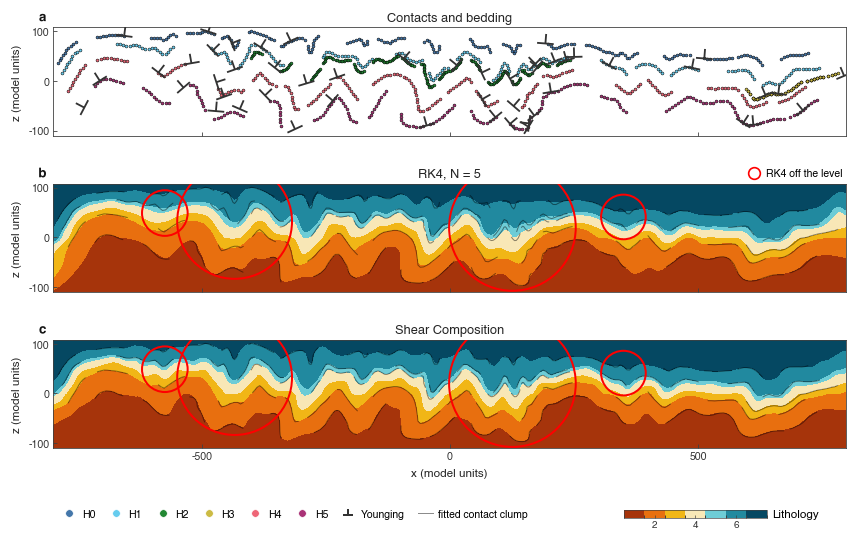

In [2]:
POINT_SIZE = 3.0
YOUNGING_LENGTH = 40.0
FITS = (("rk4", "RK4"), ("shear", "Shear Composition"))

fits = {k: np.load(bfi.results_dir(k, EQ_FORM) / "fit.npz") for k, _ in FITS}
settings = {k: json.loads((bfi.results_dir(k, EQ_FORM) / "summary.json").read_text()) for k, _ in FITS}
litho_all = np.concatenate([f["lithology"].ravel() for f in fits.values()])
cmap_litho, norm_litho = figstyle.litho_cmap(np.unique(litho_all))
# The stretches of each trace that the fit saw, each drawn once: clumps on a short trace can
# overlap, and overlapping translucent lines would darken.
clump_runs = []
for full, used in zip(horizons_full, horizons):
    seen = np.linalg.norm(full[:, None, :] - used[None, :, :], axis=-1).min(axis=1) <= 1e-6
    edges = np.flatnonzero(np.diff(np.r_[0, seen.astype(int), 0]))
    clump_runs += [full[i:j] for i, j in zip(edges[::2], edges[1::2]) if j - i > 1]
data_kw = dict(colors=horizon_colors, scatter_s=POINT_SIZE, quiver_scale=1.0 / YOUNGING_LENGTH, legend=False)

def restored_depth_residual(fit):
    """|restored depth − horizon mean| at each fitted contact. The mean is the level the equality term fits."""
    xy, residual = [], []
    for i, (full, used) in enumerate(zip(horizons_full, horizons)):
        restored = fit[f"restored_{i}"]
        nearest = np.linalg.norm(full[:, None, :] - used[None, :, :], axis=-1).argmin(axis=0)
        depth = restored[nearest, 1]
        xy.append(used)
        residual.append(np.abs(depth - depth.mean()))
    return np.vstack(xy), np.concatenate(residual)

contact_xy, residual_shear = restored_depth_residual(fits["shear"])
_, residual_rk4 = restored_depth_residual(fits["rk4"])
# Inside the shear fit's own scatter, and further from the level under RK4 than any shear residual.
shear_holds = np.quantile(residual_shear, 0.95)
rk4_misses = (residual_shear <= shear_holds) & (residual_rk4 > residual_shear.max())
missed = contact_xy[rk4_misses][np.argsort(contact_xy[rk4_misses, 0])]
# One circle per stretch of the section, not per contact. A lone contact is not an area.
X_GAP, MIN_COUNT, PAD, MIN_RADIUS = 40.0, 3, 12.0, 45.0
breaks = np.flatnonzero(np.diff(missed[:, 0]) > X_GAP)
misfit_areas = []
for a, b in zip(np.r_[0, breaks + 1], np.r_[breaks, len(missed) - 1]):
    clump = missed[a:b + 1]
    if len(clump) < MIN_COUNT:
        continue
    centre = clump.mean(axis=0)
    radius = max(float(np.linalg.norm(clump - centre, axis=1).max()) + PAD, MIN_RADIUS)
    misfit_areas.append((centre, radius, len(clump)))
print(f"RK4 off the level where shear holds it: {len(missed)} contacts in {len(misfit_areas)} areas "
      f"(shear residual ≤ {shear_holds:.2f}, RK4 residual > {residual_shear.max():.2f} {UNIT})")
for centre, radius, n in misfit_areas:
    print(f"  x {centre[0]:.0f}, z {centre[1]:.0f}, radius {radius:.0f} ({n} contacts)")

fig, grid = figstyle.comparison_grid(1 + len(FITS), 1, xlim=xlim, zlim=zlim, panel=12.0)
ax = grid[0]
figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, **data_kw)
figstyle.format_section_ax(ax, unit=UNIT, xlabel=False, title="Contacts and bedding")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[0])

for i, (key, label) in enumerate(FITS, start=1):
    ax = grid[i]
    im_litho = _field(ax, fits[key]["lithology"], cmap_litho, norm=norm_litho)
    for run in clump_runs:
        ax.plot(run[:, 0], run[:, 1], color="k", lw=0.6, alpha=0.45, solid_capstyle="round", zorder=3)
    for centre, radius, _n in misfit_areas:
        ax.add_patch(plt.Circle(centre, radius, fill=False, ec="red", lw=1.2, zorder=5))
    if key == "rk4":
        ax.legend(handles=[plt.Line2D([], [], linestyle="none", marker="o", markersize=7,
                                      markerfacecolor="none", markeredgecolor="red", markeredgewidth=1.0,
                                      label="RK4 off the level")],
                  loc="lower right", bbox_to_anchor=(1.0, 1.02), frameon=False, borderaxespad=0.0)
    figstyle.format_section_ax(ax, unit=UNIT, xlabel=i == len(FITS), title=f"{label}, N = {settings[key]['n_steps']}" if i == 1 else f"{label}")
    figstyle.set_view(ax, xlim, zlim)
    figstyle.hide_cbar(grid.cbar_axes[i])

for ax, letter in zip(grid.axes, "abc"):
    figstyle.panel_label(ax, letter)
# Under panel c, one row: the legend, then a small lithology colour bar for both fits (they share the scale).
LEGEND_DROP = 0.55          # inches below panel c
handles = figstyle.constraint_handles(horizon_colors, horizon_names)
handles.append(plt.Line2D([], [], color="k", lw=0.6, alpha=0.45, label="fitted contact clump"))
pos, fig_w, fig_h = grid.axes[-1].get_position(), fig.get_figwidth(), fig.get_figheight()
y_row = pos.y0 - LEGEND_DROP / fig_h
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(pos.x0, y_row), ncol=len(handles), frameon=False)
cax = fig.add_axes((pos.x0 + 0.72 * pos.width, y_row - 0.03 / fig_h, 0.18 * pos.width, 0.06 / fig_h))
figstyle.add_cbar(cax, im_litho, "")
cax.text(1.04, 0.5, "Lithology", transform=cax.transAxes, ha="left", va="center",
         fontproperties=figstyle._fp(size=10))

written = figstyle.save(fig, FIG_DIR / "fig04_big_fold")
print("wrote", *written, sep="\n  ")
plt.show()

## Numbers for the text

From `summary.json` (written by 04b).

In [3]:
s = summary["shortening"]
sd = list(summary["restored_depth_sd"].values())
full_length = [i for i, h in enumerate(horizons_full) if bfi.width(h) > 1000]
print(f"integrator {INTEGRATOR}, n_steps {summary['n_steps']}")
print(f"restored-depth sd per horizon {min(sd):.1f}–{max(sd):.1f} {UNIT}; in stratigraphic order: {summary['in_order']}")
print(f"max |det F - 1| = {summary['max_abs_det_minus_1']:.1e}")
print(f"full-length horizons {[horizon_names[i] for i in full_length]}: restore "
      f"{min(np.asarray(s['from_restored'])[full_length]):.1f}–{max(np.asarray(s['from_restored'])[full_length]):.1f}% wider; "
      f"arc lengths imply {min(np.asarray(s['from_arc'])[full_length]):.1f}–{max(np.asarray(s['from_arc'])[full_length]):.1f}%; "
      f"benchmark {s['benchmark']:.1f}%")
print(f"median strain axial ratio {summary['strain_Rs_median']:.2f}")


integrator shear, n_steps 0
restored-depth sd per horizon 0.3–6.1 model units; in stratigraphic order: True
max |det F - 1| = 7.2e-07
full-length horizons ['H0', 'H1', 'H4', 'H5']: restore -0.3–5.8% wider; arc lengths imply 15.3–26.2%; benchmark 27.8%
median strain axial ratio 2.16


## Numbers quoted in the main text: distance of the digitised contacts from the fitted ones

Both saved fits are reloaded (`restore_field.pt`, rebuilt with the settings in `fit_settings.json`)
and every point of the dense digitised traces is scored by its first-order distance from its
horizon's level surface, `|ψ − c| / |∇ψ|`, as for Hartland Quay and Claudius. `c` is the
horizon's isovalue, set by its clumps as in `04b`. A median over all points is dominated by the long, open folds, which both fits follow, so the
points are also scored at the tight hinges alone: where the digitised trace's radius of curvature
is below `TIGHT` model units, half the band's shortest wavelength. Reported for all points,
for the tight hinges, and for the points more than `SEEN` model units from any clump (the parts of
the traces the fit did not see).

In [7]:
import torch
import curlew
from curlew.core import CSet, HSet
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity

curlew.device, curlew.dtype, curlew.default_dim = "cpu", torch.float32, 2
SEEN = 2.0   # model units: trace points closer than this to a clump count as seen by the fit
TIGHT = 0.5 * json.loads((RES_DIR / "fit_settings.json").read_text())["lsr"][0]   # tight hinge: radius below L_min / 2


def radius_of_curvature(trace):
    # Of the digitised trace, from the turn of its tangent per unit length, smoothed over three points.
    t = np.gradient(trace, axis=0)
    heading = np.unwrap(np.arctan2(t[:, 1], t[:, 0]))
    s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(trace, axis=0), axis=1))]
    k = np.convolve(np.abs(np.gradient(heading, s)), np.ones(3) / 3, mode="same")
    return 1.0 / np.maximum(k, 1e-12)


iq_pairs = [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]


def load_fit(integrator):
    # Rebuild 04b's restore event with the saved settings and load the fitted parameters.
    res = bfi.results_dir(integrator, EQ_FORM)
    S = json.loads((res / "fit_settings.json").read_text())
    C = CSet(gp=gp, gv=gv, eq=horizons, iq=(S["iq_samples"], iq_pairs))
    velocity = euler_velocity(2, n_features=S["n_features"], n_directions=S["n_directions"],
                              length_scale_range=tuple(S["lsr"]), stream="alpha", activation="cubic",
                              seed=S["fourier_seed"], energy_normalised=S["energy_normalised"])
    event = restore("big_fold_restore", C=C, H=HSet().zero(**S["weights"]), velocity=velocity,
                    n_steps=S["n_steps"], integrator=integrator, depth_axis=1, init_std=S["init_std"],
                    sigma_floor=0., signed_normals=True, learning_rate=S["lr_adam"],
                    pin=torch.zeros(2, dtype=curlew.dtype))
    event.field.load_state_dict(torch.load(res / "restore_field.pt", map_location="cpu"))
    for name, h in zip(reversed(horizon_names), reversed(horizons)):
        event.addIsosurface(name, seed=h)
    return event


def level_distance(event, pts, iso):
    g, v = event.field.gradient(torch.as_tensor(pts, dtype=curlew.dtype), normalize=False, return_value=True)
    g, v = g.detach().numpy(), v.detach().numpy().ravel()
    return np.abs(v - iso) / np.maximum(np.linalg.norm(g, axis=1), 1e-12)


unseen = [np.min(np.linalg.norm(f[:, None] - h[None], axis=2), axis=1) > SEEN
          for f, h in zip(horizons_full, horizons)]
tight = [radius_of_curvature(f) < TIGHT for f in horizons_full]
print(f"tight hinges (radius < {TIGHT:.0f} {UNIT}): {sum(int(t.sum()) for t in tight)} trace points, per horizon "
      + ", ".join(f"{n} {int(t.sum())}" for n, t in zip(horizon_names, tight)))


def summary(d):
    return f"median {np.median(d):.1f}, 90% within {np.percentile(d, 90):.1f}"


for integrator in bfi.INTEGRATORS:
    event = load_fit(integrator)
    iso = {str(k): float(v) for k, v in event.getIsovalues().items()}
    dist = [level_distance(event, f, iso[n]) for n, f in zip(horizon_names, horizons_full)]
    pick = lambda masks: np.concatenate([d[m] for d, m in zip(dist, masks)])
    print(f"{integrator:>5} ({UNIT}): all {summary(np.concatenate(dist))} | tight hinges {summary(pick(tight))} | "
          f"unseen {summary(pick(unseen))}")
    print("       per horizon median, all / tight: "
          + ", ".join(f"{n} {np.median(x):.1f} / {np.median(x[t]) if t.any() else float('nan'):.1f}"
                      for n, x, t in zip(horizon_names, dist, tight)))


tight hinges (radius < 33 model units): 592 trace points, per horizon H0 134, H1 129, H2 141, H3 4, H4 82, H5 102
shear (model units): all median 0.6, 90% within 3.9 | tight hinges median 0.9, 90% within 4.2 | unseen median 2.0, 90% within 7.5
       per horizon median, all / tight: H0 0.8 / 1.2, H1 0.7 / 0.9, H2 0.5 / 0.7, H3 0.2 / 0.3, H4 0.7 / 0.8, H5 0.5 / 1.0
  rk4 (model units): all median 1.2, 90% within 5.2 | tight hinges median 2.0, 90% within 6.5 | unseen median 2.7, 90% within 9.5
       per horizon median, all / tight: H0 1.3 / 2.7, H1 1.4 / 2.3, H2 1.2 / 1.6, H3 0.3 / 0.4, H4 1.2 / 1.5, H5 0.9 / 1.8
